In [ ]:
# @title Imports and configurations
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import itertools
import os

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
batch_size = 128
number_of_epochs = 20
number_of_classes = 10
torch.manual_seed(43)
if device.type == 'cuda':
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
# @title Utility functions
def plot_metrics(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    ax[0].plot(history['train_loss'], label='Train Loss')
    ax[0].plot(history['val_loss'], label='Validation Loss')
    ax[0].set_title(f'{title} - Loss vs. Epoch')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Loss')
    ax[0].legend()
    ax[0].grid(True)

    ax[1].plot(history['train_acc'], label='Train Accuracy')
    ax[1].plot(history['val_acc'], label='Validation Accuracy')
    ax[1].set_title(f'{title} - Accuracy vs. Epoch')
    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Accuracy')
    ax[1].legend()
    ax[1].grid(True)

    plt.show()

def plot_confusion_matrix(cm, classes, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(8, 8))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, model_name):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0

    print(f"==== Training {model_name} ====")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        val_loss, val_acc, _, _ = evaluate_model(model, val_loader, criterion)

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = correct_train / total_train

        print(f"Epoch {epoch+1}/{num_epochs}: "
              f"Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)

        if epoch_acc > val_acc + 0.05:
            print("<><> Analysis: Potential Overfitting (Train Acc >> Val Acc)")
        elif epoch_acc < val_acc - 0.05:
            print("<><> Analysis: Potential Underfitting (Train Acc << Val Acc)")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f'{model_name}_best.pth')

    print(f"==== Training finished. Best Val Acc: {best_val_acc:.4f} ====")
    return history

def evaluate_model(model, data_loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(data_loader)
    accuracy = correct / total

    return avg_loss, accuracy, all_labels, all_preds

def final_report(model, test_loader, model_name, criterion):
    test_loss, test_acc, true_labels, pred_labels = evaluate_model(model, test_loader, criterion)

    print(f"==== {model_name} report ====")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")

    cm = confusion_matrix(true_labels, pred_labels)
    class_names = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
    plot_confusion_matrix(cm, class_names, title=f'{model_name} Confusion Matrix')

    return test_loss, test_acc

NameError: name 'plt' is not defined

In [ ]:
# @title Preprocess and augmentation
transform_no_aug = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset_no_aug = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_no_aug)
train_dataset_with_aug = datasets.CIFAR10(root='./data', train=True, download=False, transform=transform_aug)
val_test_dataset = datasets.CIFAR10(root='./data', train=False, download=False, transform=transform_no_aug)

val_dataset, test_dataset = torch.utils.data.random_split(val_test_dataset, [5000, 5000])

train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=batch_size, shuffle=True, num_workers=4)
train_loader_with_aug = DataLoader(train_dataset_with_aug, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

print("Data loaded.")
print("Baseline Train size:", len(train_dataset_no_aug))
print("Augmented Train size:", len(train_dataset_with_aug))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_dataset))

100%|██████████| 170M/170M [00:06<00:00, 26.5MB/s] 


Extracting ./data/cifar-10-python.tar.gz to ./data
Data loaded.
Baseline Train size: 50000
Augmented Train size: 50000
Validation size: 5000
Test size: 5000


In [ ]:
# @title Baseline model
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(8 * 8 * 64, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
# @title Deeper model
class DeepCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(DeepCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.BatchNorm2d(64),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.BatchNorm2d(128),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4 * 4 * 256, 1024),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
# @title Residual connections model
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out += self.shortcut(residual)
        out = self.relu(out)
        return out

In [ ]:
# @title Custom ResNet (using Residual Connections)
class ResNetCustom(nn.Module):
    def __init__(self, block, num_blocks, num_classes=10):
        super(ResNetCustom, self).__init__()
        self.in_channels = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)

        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_channels, out_channels, stride))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avg_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

def CustomResNet14():
    return ResNetCustom(ResidualBlock, [1, 1, 1, 1])

In [ ]:
# @title ResNet-18
def get_resnet18_model(pretrained=True):
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)

    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, number_of_classes)

    return model

def setup_transfer_learning(model, phase):
    if phase == 'freeze':
        print("Transfer Learning: Freezing all layers except the final FC layer.")
        for name, param in model.named_parameters():
            if 'fc' not in name:
                param.requires_grad = False
            else:
                param.requires_grad = True
    elif phase == 'partial_freeze':
        print("Transfer Learning: Partial Freeze (Freezing initial layers, training layer3, layer4, and FC).")
        for name, param in model.named_parameters():
            if 'conv1' in name or 'bn1' in name or 'layer1' in name or 'layer2' in name:
                param.requires_grad = False
            else:
                param.requires_grad = True
    elif phase == 'finetune':
        print("Transfer Learning: Fine-Tuning (All layers trainable).")
        for param in model.parameters():
            param.requires_grad = True

    return model

In [ ]:
results_summary = {}
criterion = nn.CrossEntropyLoss()

==== Training CustomCNN_NoAug ====
Epoch 1/20: Train Loss: 1.4662, Train Acc: 0.4671 | Val Loss: 1.1594, Val Acc: 0.5888
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 1.1038, Train Acc: 0.6054 | Val Loss: 0.9413, Val Acc: 0.6590
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 3/20: Train Loss: 0.9329, Train Acc: 0.6693 | Val Loss: 0.8515, Val Acc: 0.7038
Epoch 4/20: Train Loss: 0.8183, Train Acc: 0.7107 | Val Loss: 0.8209, Val Acc: 0.7054
Epoch 5/20: Train Loss: 0.7377, Train Acc: 0.7416 | Val Loss: 0.7691, Val Acc: 0.7280
Epoch 6/20: Train Loss: 0.6513, Train Acc: 0.7738 | Val Loss: 0.7486, Val Acc: 0.7404
Epoch 7/20: Train Loss: 0.5839, Train Acc: 0.7938 | Val Loss: 0.7523, Val Acc: 0.7442
Epoch 8/20: Train Loss: 0.5107, Train Acc: 0.8197 | Val Loss: 0.7600, Val Acc: 0.7384
<><> Analysis: Potential Overfitting (Train Acc >> Val Acc)
Epoch 9/20: Train Loss: 0.4493, Train Acc: 0.8424 | Val Loss: 0.7765, Val Acc: 0.7478
<><> Anal

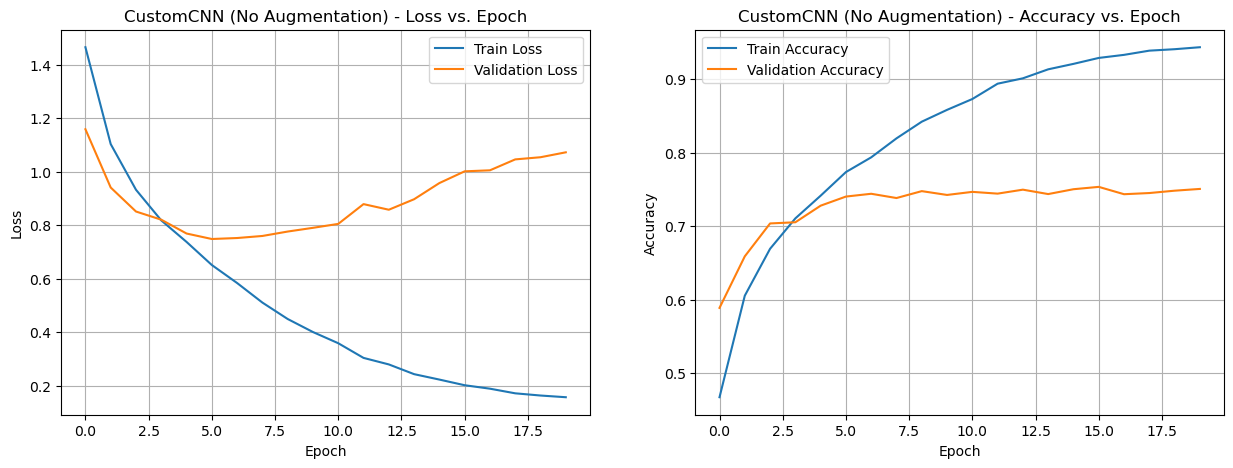

==== CustomCNN_NoAug report ====
Test Loss: 1.1492
Test Accuracy: 0.7408


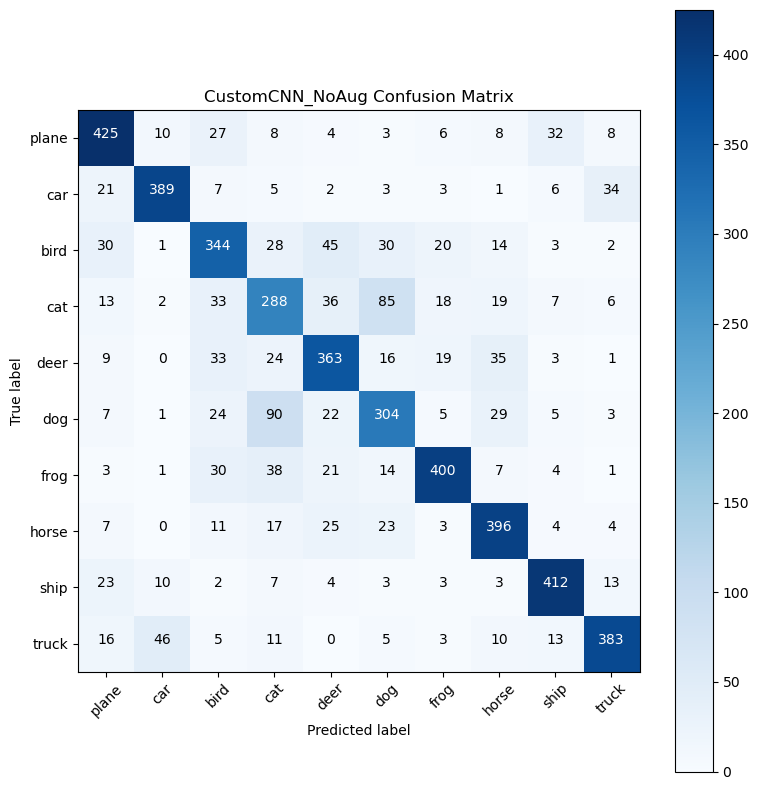

In [ ]:
# @title Phase 1: Without augmentation
model_cnn_no_aug = CustomCNN(number_of_classes).to(device)
optimizer_cnn_no_aug = optim.Adam(model_cnn_no_aug.parameters(), lr=0.001)

history_cnn_no_aug = train_model(model_cnn_no_aug, train_loader_no_aug, val_loader,
                                  criterion, optimizer_cnn_no_aug, number_of_epochs, "CustomCNN_NoAug")
plot_metrics(history_cnn_no_aug, "CustomCNN (No Augmentation)")
test_loss, test_acc = final_report(model_cnn_no_aug, test_loader, "CustomCNN_NoAug", criterion)
results_summary['CustomCNN_NoAug'] = {'Acc': test_acc, 'Loss': test_loss}

==== Training CustomCNN_WithAug ====
Epoch 1/20: Train Loss: 1.6915, Train Acc: 0.3821 | Val Loss: 1.3035, Val Acc: 0.5328
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 1.3727, Train Acc: 0.5044 | Val Loss: 1.0736, Val Acc: 0.6136
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 3/20: Train Loss: 1.2342, Train Acc: 0.5613 | Val Loss: 0.9692, Val Acc: 0.6562
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 4/20: Train Loss: 1.1542, Train Acc: 0.5875 | Val Loss: 0.9179, Val Acc: 0.6820
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 5/20: Train Loss: 1.0961, Train Acc: 0.6125 | Val Loss: 0.8615, Val Acc: 0.6974
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 6/20: Train Loss: 1.0429, Train Acc: 0.6324 | Val Loss: 0.8252, Val Acc: 0.7128
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 7/20: Train Loss: 1.0111, Train Acc: 0.6433 | Val Loss: 0.8118, Val Acc: 0.

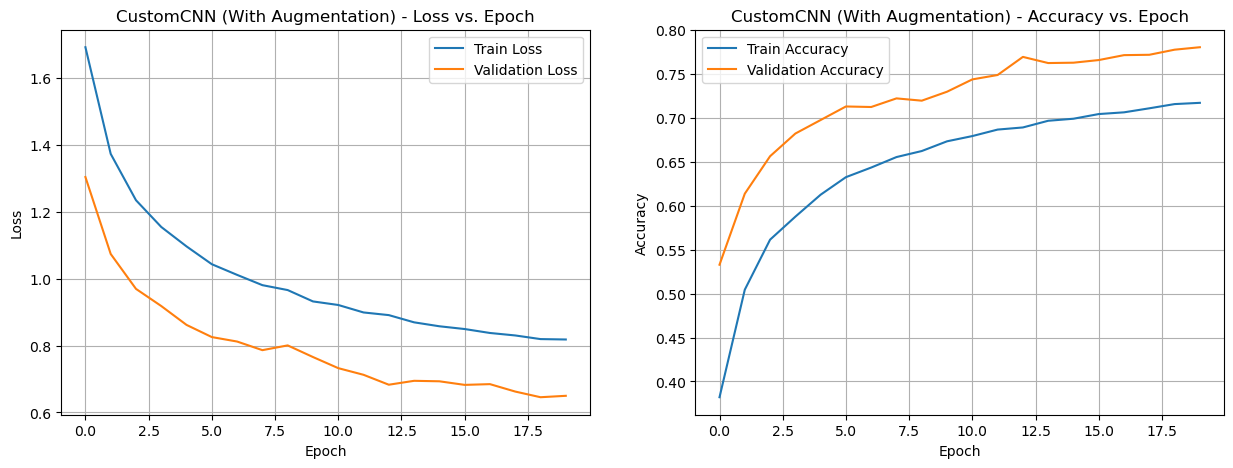

==== CustomCNN_WithAug report ====
Test Loss: 0.6717
Test Accuracy: 0.7682


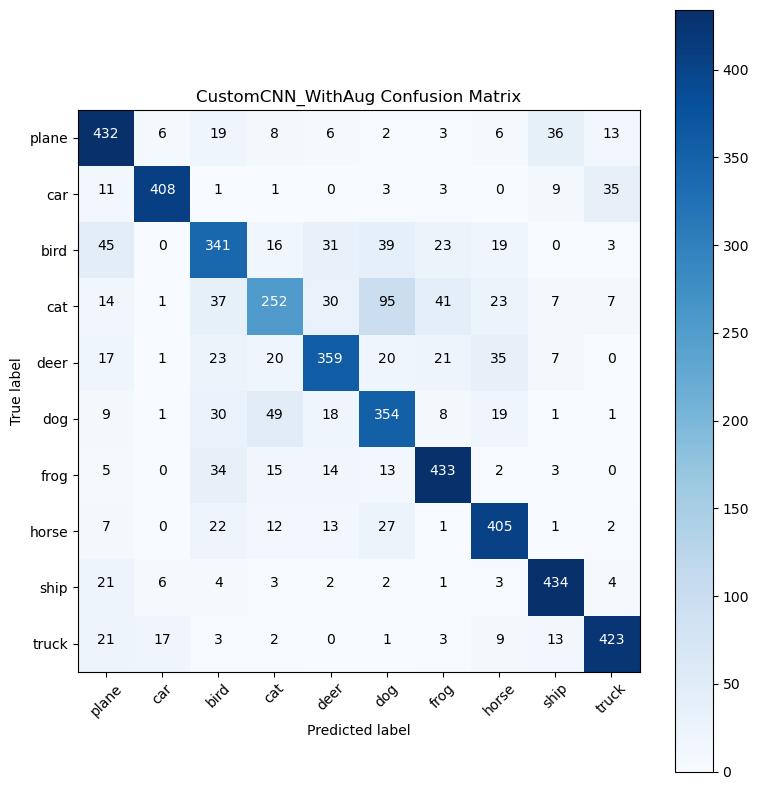

In [ ]:
# @title Phase 1: With augmentation
model_cnn_aug = CustomCNN(number_of_classes).to(device)
optimizer_cnn_aug = optim.Adam(model_cnn_aug.parameters(), lr=0.001)

history_cnn_aug = train_model(model_cnn_aug, train_loader_with_aug, val_loader,
                              criterion, optimizer_cnn_aug, number_of_epochs, "CustomCNN_WithAug")
plot_metrics(history_cnn_aug, "CustomCNN (With Augmentation)")
test_loss, test_acc = final_report(model_cnn_aug, test_loader, "CustomCNN_WithAug", criterion)
results_summary['CustomCNN_WithAug'] = {'Acc': test_acc, 'Loss': test_loss}

#مقایسه‌ی بین مدل بدون augmentation و با augmentation
همانطور که از نمودار روند یادگیری این دو مدل پیداست، مدل بدون augmentation دچار overfitting شده و دقت validation آن بعد از مدتی، پیشرفت نکرده و خطای آن افزایش پیدا کرده است. مدل با augmentation اختلاف کمتری بین دقت و خطای validation و train تجربه کرده و به همین دلیل، در نهایت دقت بیشتری دارد.

==== Training DeepCNN_WithAug ====
Epoch 1/20: Train Loss: 1.5710, Train Acc: 0.4316 | Val Loss: 0.9909, Val Acc: 0.6470
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 0.9775, Train Acc: 0.6564 | Val Loss: 0.7805, Val Acc: 0.7298
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 3/20: Train Loss: 0.7870, Train Acc: 0.7278 | Val Loss: 0.6431, Val Acc: 0.7786
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 4/20: Train Loss: 0.6935, Train Acc: 0.7633 | Val Loss: 0.5537, Val Acc: 0.8120
Epoch 5/20: Train Loss: 0.6273, Train Acc: 0.7842 | Val Loss: 0.5199, Val Acc: 0.8204
Epoch 6/20: Train Loss: 0.5832, Train Acc: 0.8007 | Val Loss: 0.5108, Val Acc: 0.8268
Epoch 7/20: Train Loss: 0.5409, Train Acc: 0.8160 | Val Loss: 0.4732, Val Acc: 0.8332
Epoch 8/20: Train Loss: 0.5129, Train Acc: 0.8232 | Val Loss: 0.4613, Val Acc: 0.8422
Epoch 9/20: Train Loss: 0.4827, Train Acc: 0.8356 | Val Loss: 0.4710, Val Acc: 0.8522
Epoch 10

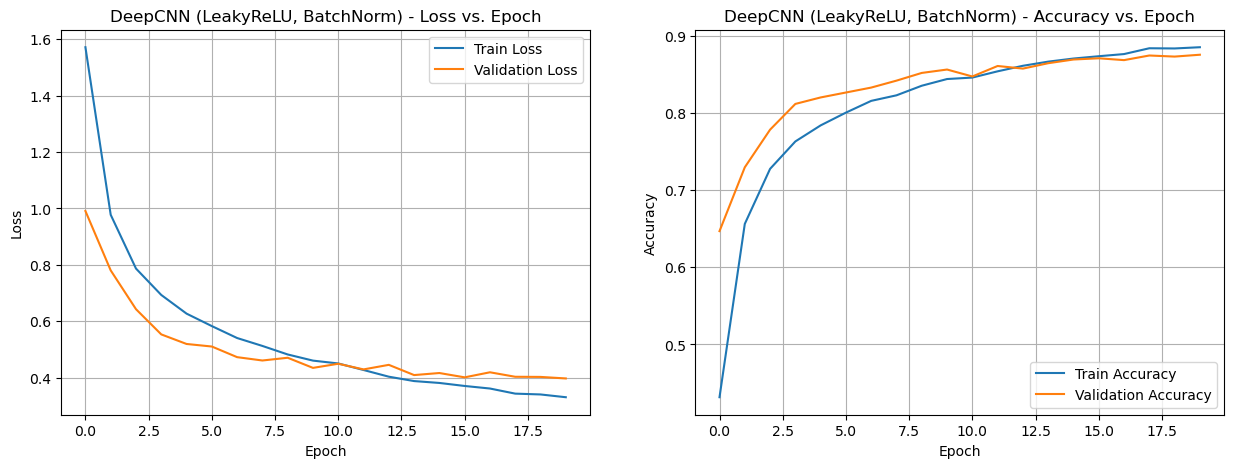

==== DeepCNN_WithAug report ====
Test Loss: 0.3927
Test Accuracy: 0.8752


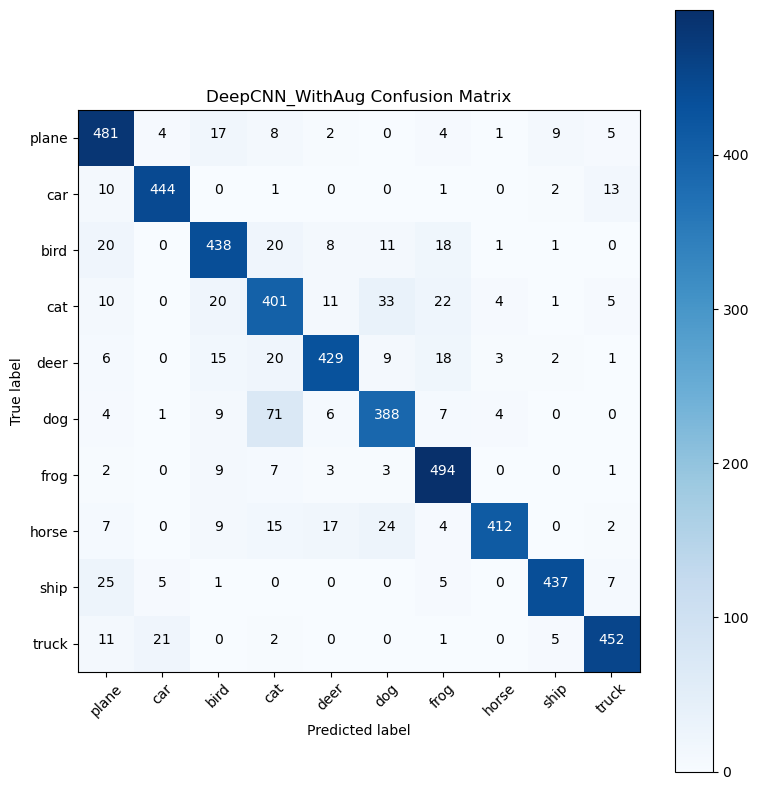

In [ ]:
# @title Phase 2: Deeper model
model_deep_cnn = DeepCNN(number_of_classes).to(device)
optimizer_deep_cnn = optim.Adam(model_deep_cnn.parameters(), lr=0.001)

history_deep_cnn = train_model(model_deep_cnn, train_loader_with_aug, val_loader,
                                criterion, optimizer_deep_cnn, number_of_epochs, "DeepCNN_WithAug")
plot_metrics(history_deep_cnn, "DeepCNN (LeakyReLU, BatchNorm)")
test_loss, test_acc = final_report(model_deep_cnn, test_loader, "DeepCNN_WithAug", criterion)
results_summary['DeepCNN_WithAug'] = {'Acc': test_acc, 'Loss': test_loss}

یک مدل عمیق‌تر برای مقایسه با مدل قبلی در نظر گرفته شده. همانطور که از خروجی این مدل مشخص است، دقت به مراتب افزایش پیدا کرده و در مقابل، منابع مورد نیاز برای آموزش مدل نیز افزایش پیدا کرده است.

==== Training CustomResNet14 ====
Epoch 1/20: Train Loss: 1.4758, Train Acc: 0.4588 | Val Loss: 1.0539, Val Acc: 0.6160
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 0.9969, Train Acc: 0.6452 | Val Loss: 0.8829, Val Acc: 0.6892
Epoch 3/20: Train Loss: 0.7892, Train Acc: 0.7215 | Val Loss: 0.8843, Val Acc: 0.7046
Epoch 4/20: Train Loss: 0.6646, Train Acc: 0.7687 | Val Loss: 0.6997, Val Acc: 0.7670
Epoch 5/20: Train Loss: 0.5887, Train Acc: 0.7959 | Val Loss: 0.6753, Val Acc: 0.7756
Epoch 6/20: Train Loss: 0.5289, Train Acc: 0.8166 | Val Loss: 0.5509, Val Acc: 0.8180
Epoch 7/20: Train Loss: 0.4789, Train Acc: 0.8334 | Val Loss: 0.4928, Val Acc: 0.8334
Epoch 8/20: Train Loss: 0.4397, Train Acc: 0.8483 | Val Loss: 0.4586, Val Acc: 0.8476
Epoch 9/20: Train Loss: 0.4086, Train Acc: 0.8601 | Val Loss: 0.4407, Val Acc: 0.8508
Epoch 10/20: Train Loss: 0.3751, Train Acc: 0.8696 | Val Loss: 0.4723, Val Acc: 0.8450
Epoch 11/20: Train Loss: 0.3540, Train Acc: 

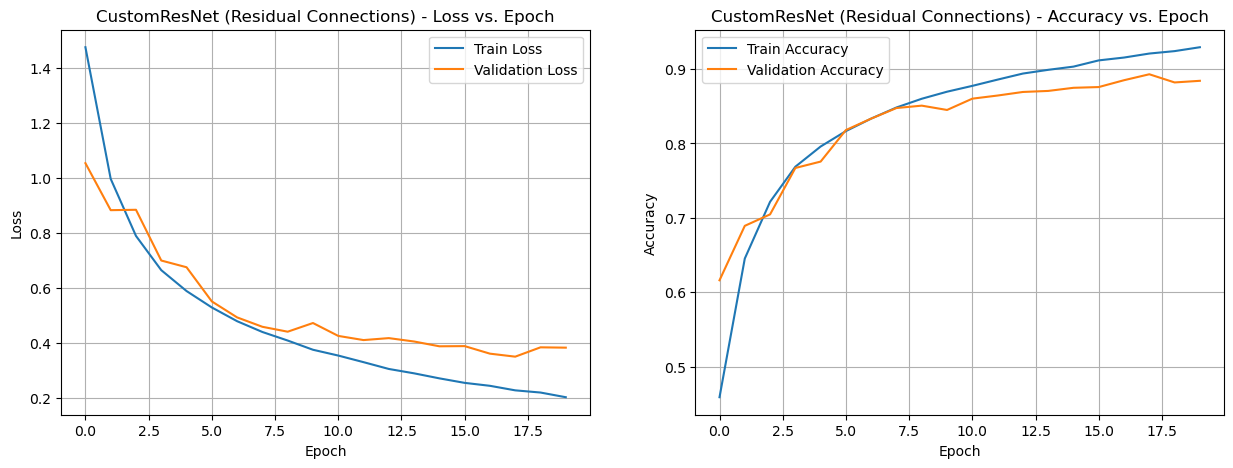

==== CustomResNet14 report ====
Test Loss: 0.3887
Test Accuracy: 0.8814


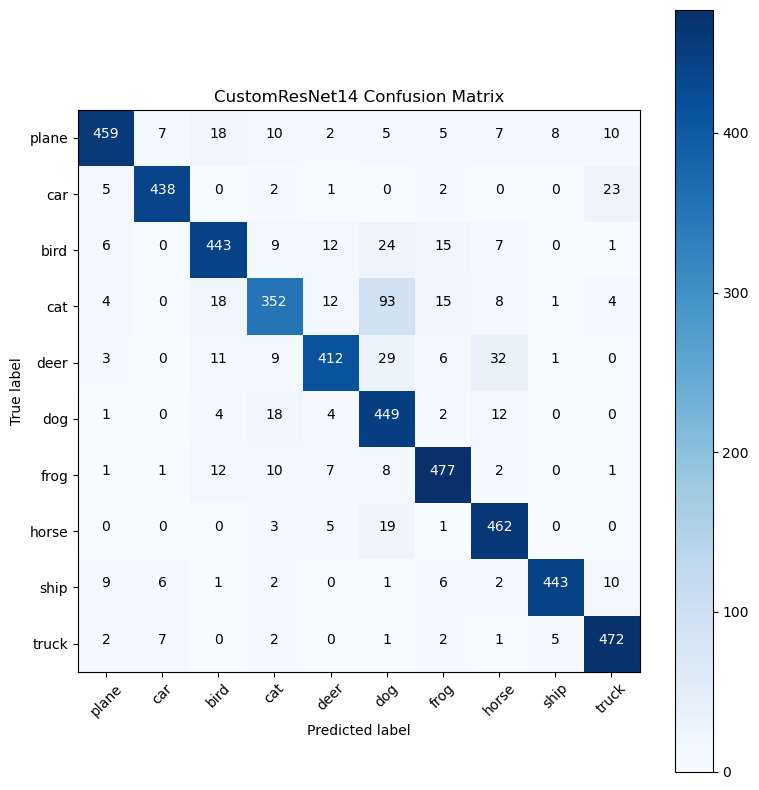

In [ ]:
# @title Phase 3: Custom ResNet (Residual connections)
model_resnet_custom = CustomResNet14().to(device)
optimizer_resnet_custom = optim.Adam(model_resnet_custom.parameters(), lr=0.001)

history_resnet_custom = train_model(model_resnet_custom, train_loader_with_aug, val_loader,
                                    criterion, optimizer_resnet_custom, number_of_epochs, "CustomResNet14")
plot_metrics(history_resnet_custom, "CustomResNet (Residual Connections)")
test_loss, test_acc = final_report(model_resnet_custom, test_loader, "CustomResNet14", criterion)
results_summary['CustomResNet14'] = {'Acc': test_acc, 'Loss': test_loss}

مدل دارای residual connections دقت بیشتری از مدل عمیق‌تر دارد. همچنین اگر روند تغییرات دقت و خطای روی داده‌ی train را بررسی کنید، متوجه پایداری بیشتر مدل دارای residual connections خواهید شد. روند افزایشی دقت و روند کاهشی خطا در مدل دارای residual connections دستخوش تغییر نشده اما مدل عمیق در بعضی از دوره‌ها، دچار کاهش (هر چند ناچیز) دقت شده است.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/jovyan/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]

Transfer Learning: Freezing all layers except the final FC layer.
==== Training ResNet18_Freeze ====


Epoch 1/5: Train Loss: 1.9536, Train Acc: 0.3316 | Val Loss: 1.9483, Val Acc: 0.3622
Epoch 2/5: Train Loss: 1.8994, Train Acc: 0.3490 | Val Loss: 1.8645, Val Acc: 0.3818
Epoch 3/5: Train Loss: 1.9080, Train Acc: 0.3517 | Val Loss: 1.8956, Val Acc: 0.3730
Epoch 4/5: Train Loss: 1.9122, Train Acc: 0.3497 | Val Loss: 1.9480, Val Acc: 0.3670
Epoch 5/5: Train Loss: 1.9177, Train Acc: 0.3494 | Val Loss: 1.8879, Val Acc: 0.3752
==== Training finished. Best Val Acc: 0.3818 ====


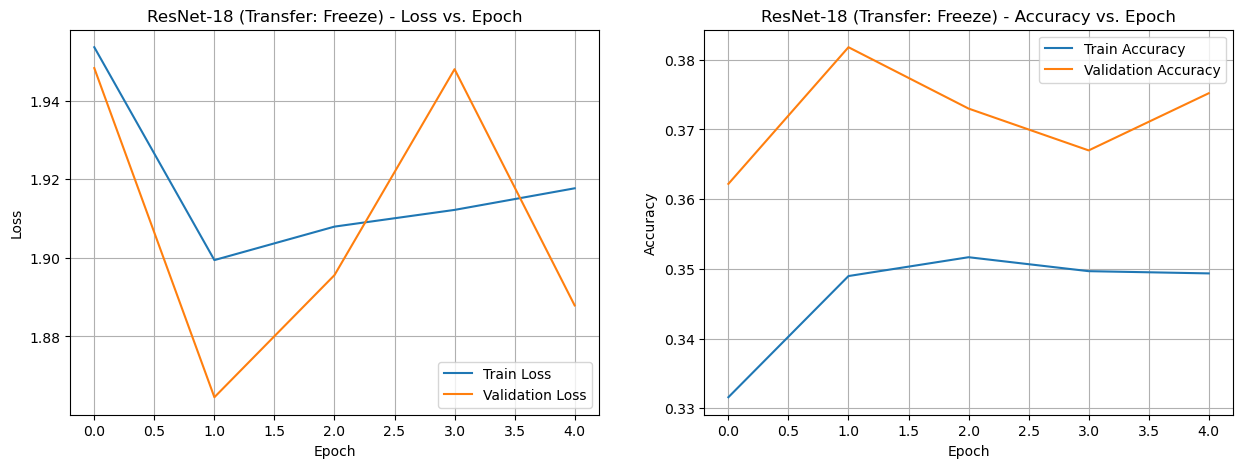

==== ResNet18_Freeze report ====
Test Loss: 1.8488
Test Accuracy: 0.3752


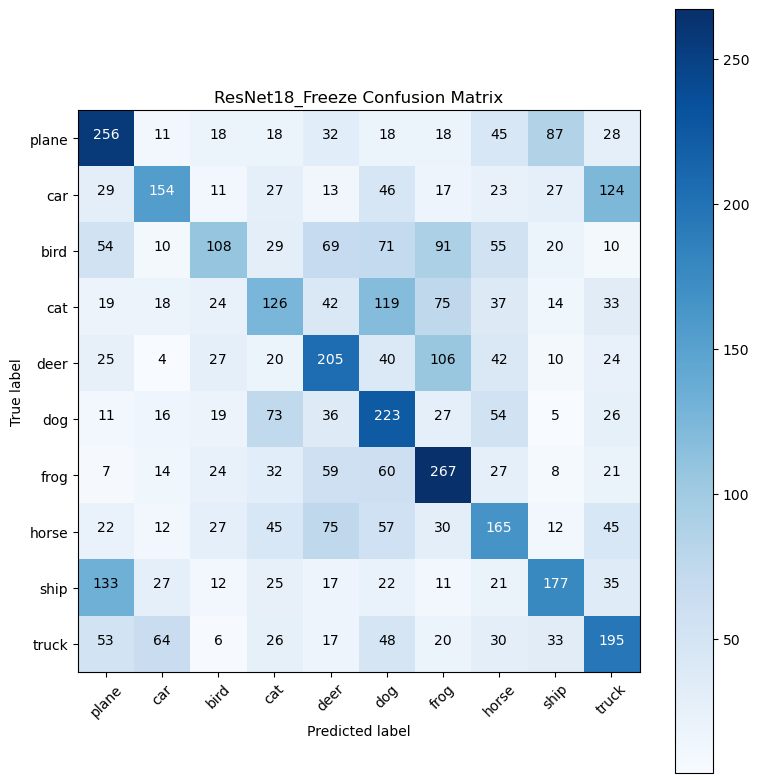

In [ ]:
# @title Phase 4: ResNet-18 frozen
model_resnet18_freeze = get_resnet18_model(pretrained=True).to(device)
model_resnet18_freeze = setup_transfer_learning(model_resnet18_freeze, 'freeze')
optimizer_resnet18_freeze = optim.Adam(model_resnet18_freeze.fc.parameters(), lr=0.005)

history_resnet18_freeze = train_model(model_resnet18_freeze, train_loader_with_aug, val_loader,
                                      criterion, optimizer_resnet18_freeze, 5, "ResNet18_Freeze")
plot_metrics(history_resnet18_freeze, "ResNet-18 (Transfer: Freeze)")
test_loss, test_acc = final_report(model_resnet18_freeze, test_loader, "ResNet18_Freeze", criterion)
results_summary['ResNet18_Freeze'] = {'Acc': test_acc, 'Loss': test_loss}

Transfer Learning: Partial Freeze (Freezing initial layers, training layer3, layer4, and FC).
==== Training ResNet18_PartialFreeze ====
Epoch 1/20: Train Loss: 1.2175, Train Acc: 0.5735 | Val Loss: 0.8920, Val Acc: 0.7006
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 0.9570, Train Acc: 0.6702 | Val Loss: 0.8241, Val Acc: 0.7136
Epoch 3/20: Train Loss: 0.8805, Train Acc: 0.6951 | Val Loss: 0.7731, Val Acc: 0.7370
Epoch 4/20: Train Loss: 0.8352, Train Acc: 0.7120 | Val Loss: 0.7424, Val Acc: 0.7452
Epoch 5/20: Train Loss: 0.8011, Train Acc: 0.7201 | Val Loss: 0.7107, Val Acc: 0.7546
Epoch 6/20: Train Loss: 0.7705, Train Acc: 0.7301 | Val Loss: 0.6947, Val Acc: 0.7578
Epoch 7/20: Train Loss: 0.7524, Train Acc: 0.7366 | Val Loss: 0.6851, Val Acc: 0.7664
Epoch 8/20: Train Loss: 0.7286, Train Acc: 0.7437 | Val Loss: 0.6765, Val Acc: 0.7670
Epoch 9/20: Train Loss: 0.7142, Train Acc: 0.7510 | Val Loss: 0.6629, Val Acc: 0.7690
Epoch 10/20: Train Loss: 0.69

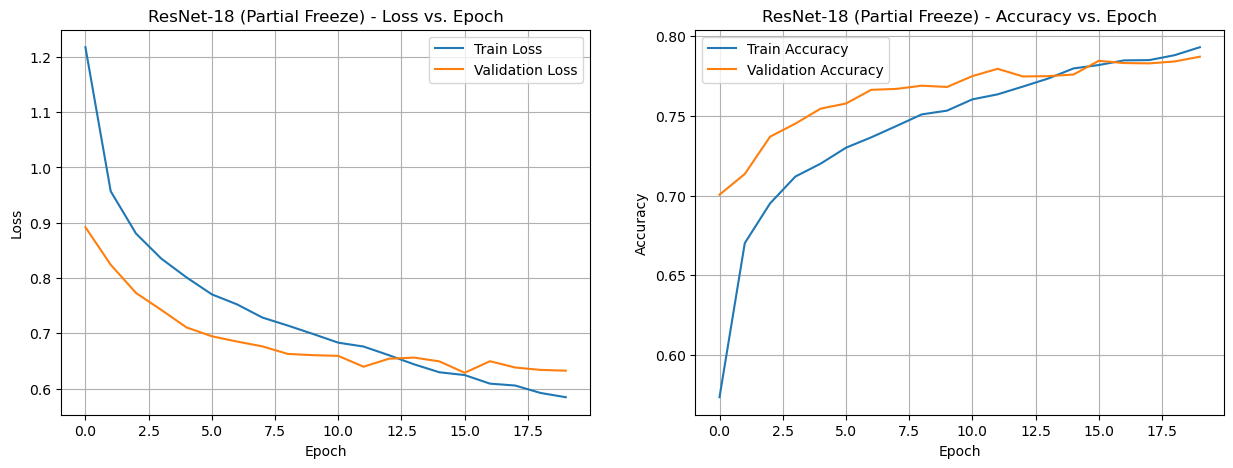

==== ResNet18_PartialFreeze report ====
Test Loss: 0.6464
Test Accuracy: 0.7780


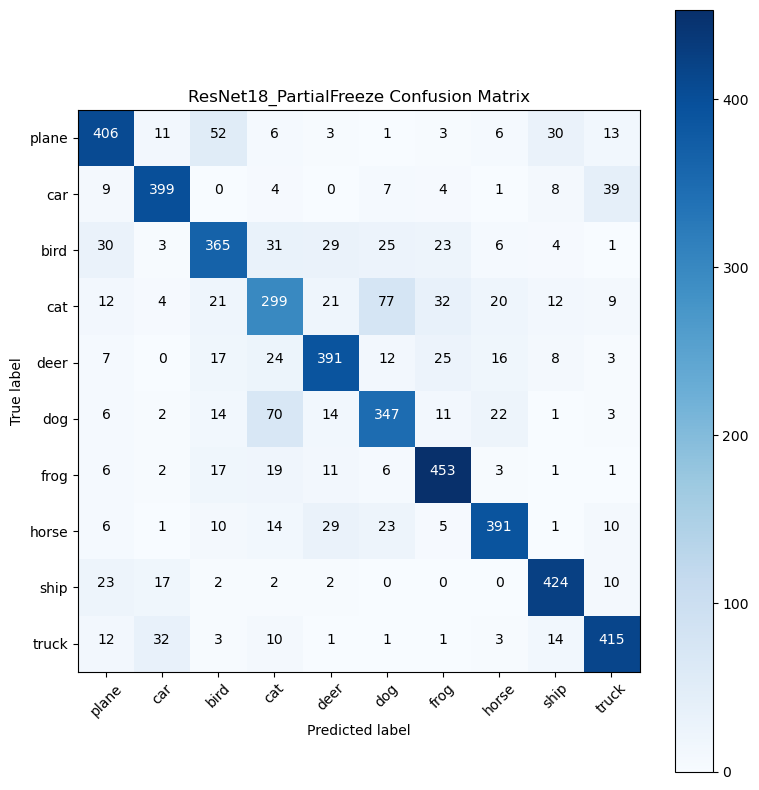

In [ ]:
# @title Phase4: ResNet-18 partially frozen
model_resnet18_partial = get_resnet18_model(pretrained=True).to(device)
model_resnet18_partial = setup_transfer_learning(model_resnet18_partial, 'partial_freeze')
optimizer_resnet18_partial = optim.Adam(filter(lambda p: p.requires_grad, model_resnet18_partial.parameters()), lr=0.001)

history_resnet18_partial = train_model(model_resnet18_partial, train_loader_with_aug, val_loader,
                                      criterion, optimizer_resnet18_partial, number_of_epochs, "ResNet18_PartialFreeze")
plot_metrics(history_resnet18_partial, "ResNet-18 (Partial Freeze)")
test_loss, test_acc = final_report(model_resnet18_partial, test_loader, "ResNet18_PartialFreeze", criterion)
results_summary['ResNet18_PartialFreeze'] = {'Acc': test_acc, 'Loss': test_loss}

Transfer Learning: Fine-Tuning (All layers trainable).
==== Training ResNet18_FineTune ====
Epoch 1/20: Train Loss: 1.2486, Train Acc: 0.5606 | Val Loss: 0.8085, Val Acc: 0.7212
<><> Analysis: Potential Underfitting (Train Acc << Val Acc)
Epoch 2/20: Train Loss: 0.8311, Train Acc: 0.7116 | Val Loss: 0.6737, Val Acc: 0.7602
Epoch 3/20: Train Loss: 0.7120, Train Acc: 0.7512 | Val Loss: 0.6031, Val Acc: 0.7944
Epoch 4/20: Train Loss: 0.6443, Train Acc: 0.7778 | Val Loss: 0.5669, Val Acc: 0.8058
Epoch 5/20: Train Loss: 0.5878, Train Acc: 0.7957 | Val Loss: 0.5547, Val Acc: 0.8098
Epoch 6/20: Train Loss: 0.5496, Train Acc: 0.8086 | Val Loss: 0.5389, Val Acc: 0.8184
Epoch 7/20: Train Loss: 0.5112, Train Acc: 0.8218 | Val Loss: 0.5243, Val Acc: 0.8202
Epoch 8/20: Train Loss: 0.4835, Train Acc: 0.8305 | Val Loss: 0.4922, Val Acc: 0.8352
Epoch 9/20: Train Loss: 0.4636, Train Acc: 0.8362 | Val Loss: 0.4844, Val Acc: 0.8358
Epoch 10/20: Train Loss: 0.4389, Train Acc: 0.8459 | Val Loss: 0.4804, Va

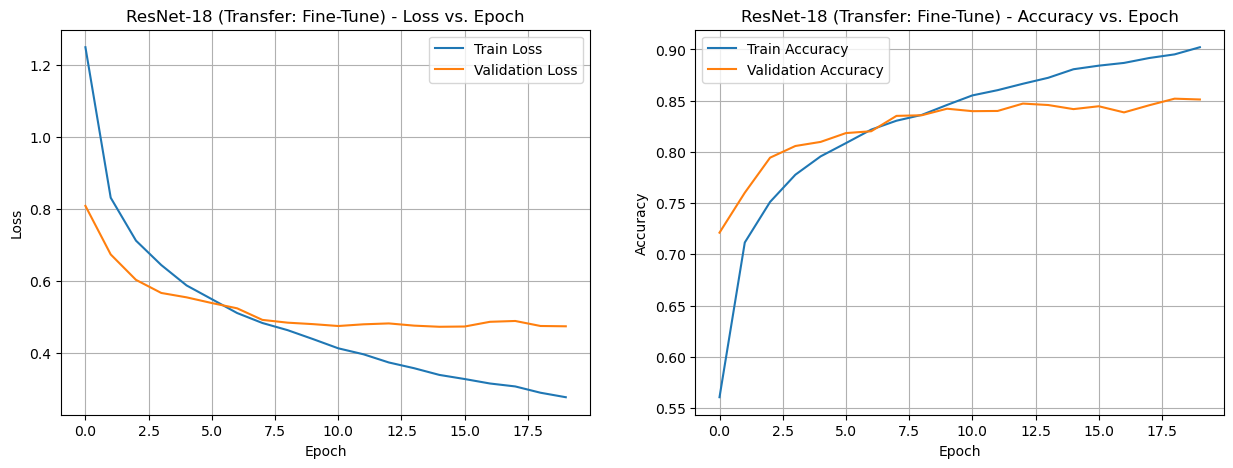

==== ResNet18_FineTune report ====
Test Loss: 0.4637
Test Accuracy: 0.8504


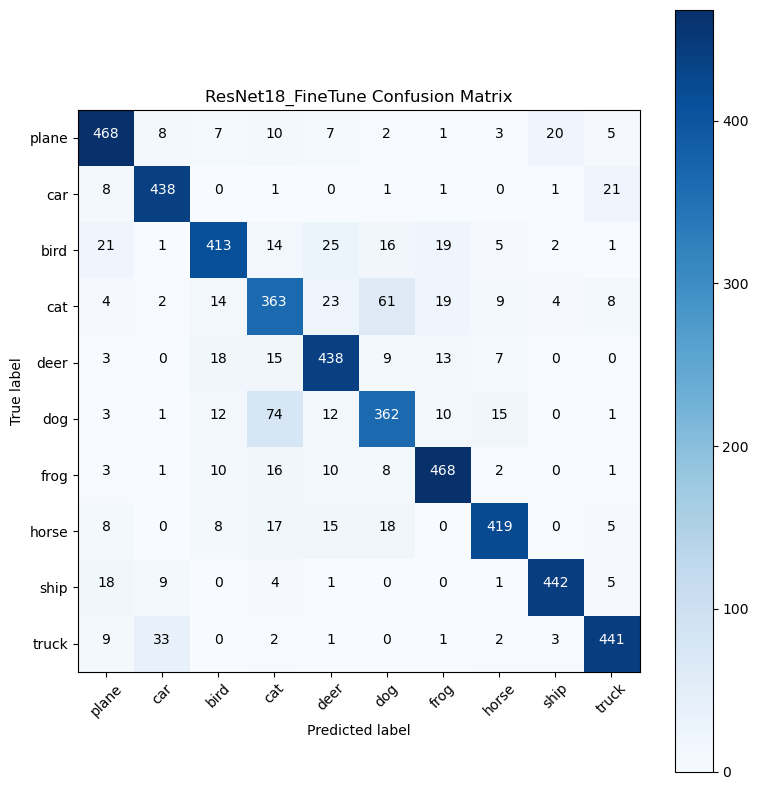

In [ ]:
# @title Phase 4: ResNet-18 fine tuned
model_resnet18_finetune = get_resnet18_model(pretrained=True).to(device)

model_resnet18_finetune = setup_transfer_learning(model_resnet18_finetune, 'finetune')
optimizer_resnet18_finetune = optim.Adam(model_resnet18_finetune.parameters(), lr=0.0001) # Low LR for fine-tuning

history_resnet18_finetune = train_model(model_resnet18_finetune, train_loader_with_aug, val_loader,
                                        criterion, optimizer_resnet18_finetune, number_of_epochs, "ResNet18_FineTune")
plot_metrics(history_resnet18_finetune, "ResNet-18 (Transfer: Fine-Tune)")
test_loss, test_acc = final_report(model_resnet18_finetune, test_loader, "ResNet18_FineTune", criterion)
results_summary['ResNet18_FineTune'] = {'Acc': test_acc, 'Loss': test_loss}

مدل ResNet در سه حالت فریز تقریبا تمامی لایه‌ها، فریز بخشی از لایه‌ها و fine tune کامل مورد بررسی قرار گرفته.

مدلی که تمامی لایه‌های (به جز لایه‌ی آخر) آن فریز شده اند، بدترین عملکرد را بین حالت‌های دیگه داشته. مدلی که تنها بخشی از لایه‌های آن فریز شده اند، عملکرد بهتری دارد اما همچنان دقت آن کمتر از دقت مدل fine tune کامل است.

مدل fine tune کامل نیاز به زمان زیادی برای آموزش دارد و باید برای آن از learning rate پایین استفاده کرد، اما در نهایت دقت خوبی خواهد داشت.

در مقایسه با مدل‌های عمیق و دارای residual connections، این مدل دقت کمتری دارد، اما دقت این سه مدل بسیار به هم نزدیک است و به همین دلیل، تفاوت چند درصدی (بین ۸۵، ۸۷ و ۸۸) قابل جشم پوشی است.

In [ ]:
# @title Phase 5: Comparison
print("="*80)
print("FINAL MODEL COMPARISON SUMMARY")
print("="*80)

print(f"{'Model Name':<25} | {'Test Accuracy':<15} | {'Test Loss':<10}")
print("-" * 80)
for name, metrics in results_summary.items():
    print(f"{name:<25} | {metrics['Acc']:.4f}{'':<11} | {metrics['Loss']:.4f}")

FINAL MODEL COMPARISON SUMMARY
Model Name                | Test Accuracy   | Test Loss 
--------------------------------------------------------------------------------
CustomCNN_NoAug           | 0.7408            | 1.1492
CustomCNN_WithAug         | 0.7682            | 0.6717
DeepCNN_WithAug           | 0.8752            | 0.3927
CustomResNet14            | 0.8814            | 0.3887
ResNet18_Freeze           | 0.3752            | 1.8488
ResNet18_PartialFreeze    | 0.7780            | 0.6464
ResNet18_FineTune         | 0.8504            | 0.4637


In [ ]:
# @title Phase 6: Grad-CAM utility
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []

        self.handles.append(target_layer.register_forward_hook(self._save_activation))
        self.handles.append(target_layer.register_backward_hook(self._save_gradient))

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        for handle in self.handles:
            handle.remove()
        self.handles = []

    def __call__(self, input_img, target_class=None):
        self.model.zero_grad()
        output = self.model(input_img)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        one_hot = torch.zeros_like(output)
        one_hot[0, target_class] = 1
        output.backward(gradient=one_hot, retain_graph=True)

        pooled_gradients = torch.mean(self.gradients, dim=[2, 3])
        weighted_activations = self.activations * pooled_gradients.unsqueeze(-1).unsqueeze(-1)
        heatmap = torch.mean(weighted_activations, dim=1)[0]

        heatmap = F.relu(heatmap)
        if torch.max(heatmap) > 0:
            heatmap /= torch.max(heatmap)

        return heatmap.cpu().numpy()

def visualize_gradcam(model, gradcam, data_loader, class_names, num_samples=3):
    print("==== Generating Grad-CAM Visualizations ====")

    unnormalize = transforms.Normalize((-1, -1, -1), (2, 2, 2))

    model.eval()
    correct_samples = []
    incorrect_samples = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for i in range(len(labels)):
                is_correct = (preds[i] == labels[i]).item()
                sample = (inputs[i].cpu(), labels[i].item(), preds[i].item())

                if is_correct and len(correct_samples) < num_samples:
                    correct_samples.append(sample)
                elif not is_correct and len(incorrect_samples) < num_samples:
                    incorrect_samples.append(sample)

                if len(correct_samples) >= num_samples and len(incorrect_samples) >= num_samples:
                    break
            if len(correct_samples) >= num_samples and len(incorrect_samples) >= num_samples:
                break

    all_samples = correct_samples + incorrect_samples

    if not all_samples:
        print("ERROR: Could not collect enough samples for Grad-CAM analysis.")
        return

    fig, axes = plt.subplots(len(all_samples), 2, figsize=(10, len(all_samples) * 4))

    if len(all_samples) == 1:
        axes = axes.reshape(1, -1)

    for i, (img_tensor, true_label, pred_label) in enumerate(all_samples):
        img_input = img_tensor.unsqueeze(0).to(device)

        try:
            low_res_cam = gradcam(img_input)
        except Exception as e:
            print(f"ERROR: Error generating CAM for sample {i}: {e}")
            continue

        cam_tensor = torch.from_numpy(low_res_cam).float().unsqueeze(0).unsqueeze(0).to(device)

        upsampled_cam = F.interpolate(cam_tensor,
                                      size=(img_tensor.shape[1], img_tensor.shape[2]),
                                      mode='bilinear',
                                      align_corners=False).squeeze().cpu().numpy()

        img_display = unnormalize(img_tensor).permute(1, 2, 0).numpy()

        axes[i, 0].imshow(img_display)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(img_display)
        axes[i, 1].imshow(upsampled_cam, cmap='jet', alpha=0.5)
        axes[i, 1].axis('off')

        status = "CORRECT" if true_label == pred_label else "INCORRECT"
        title = f"True: {class_names[true_label]}, Pred: {class_names[pred_label]} ({status})"

        axes[i, 0].set_title(title, fontsize=10)
        axes[i, 1].set_title(f"Grad-CAM (Focus Analysis)", fontsize=10)

    plt.tight_layout()
    plt.show()

def visualize_fused_gradcam(model, data_loader, layer_dict, class_names, num_samples=1):
    print("==== Generating Fused (Multi-Layer) Grad-CAM ===")

    unnormalize = transforms.Normalize((-1, -1, -1), (2, 2, 2))
    model.eval()

    samples = []
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for i in range(len(labels)):
                if len(samples) < num_samples:
                    samples.append((inputs[i], labels[i].item(), preds[i].item()))
                else:
                    break
            if len(samples) >= num_samples:
                break

    for img_idx, (img_tensor, true_label, pred_label) in enumerate(samples):
        img_input = img_tensor.unsqueeze(0).to(device)

        fused_heatmap = np.zeros((img_tensor.shape[1], img_tensor.shape[2]))

        print(f"=== Processing Image {img_idx+1}/{num_samples} ===")

        valid_layers_count = 0
        for layer_name, layer_module in layer_dict.items():
            gradcam = GradCAM(model, layer_module)
            try:
                low_res_cam = gradcam(img_input)

                cam_tensor = torch.from_numpy(low_res_cam).float().unsqueeze(0).unsqueeze(0).to(device)
                upsampled_cam = F.interpolate(cam_tensor,
                                              size=(img_tensor.shape[1], img_tensor.shape[2]),
                                              mode='bilinear',
                                              align_corners=False).squeeze().cpu().numpy()

                fused_heatmap += upsampled_cam
                valid_layers_count += 1

            except Exception as e:
                print(f"==== Skipping {layer_name}: {e} ====")
            finally:
                gradcam.remove_hooks()

        if valid_layers_count > 0:
            fused_heatmap /= valid_layers_count
            fused_heatmap = np.maximum(fused_heatmap, 0)
            if np.max(fused_heatmap) > 0:
                fused_heatmap /= np.max(fused_heatmap)

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))

        img_display = unnormalize(img_tensor.cpu()).permute(1, 2, 0).numpy()
        axes[0].imshow(img_display)
        axes[0].set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}")
        axes[0].axis('off')

        axes[1].imshow(img_display)
        axes[1].imshow(fused_heatmap, cmap='jet', alpha=0.5)
        axes[1].set_title("Fused Grad-CAM\n(All Layers Combined)")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

==== Generating Grad-CAM Visualizations ====


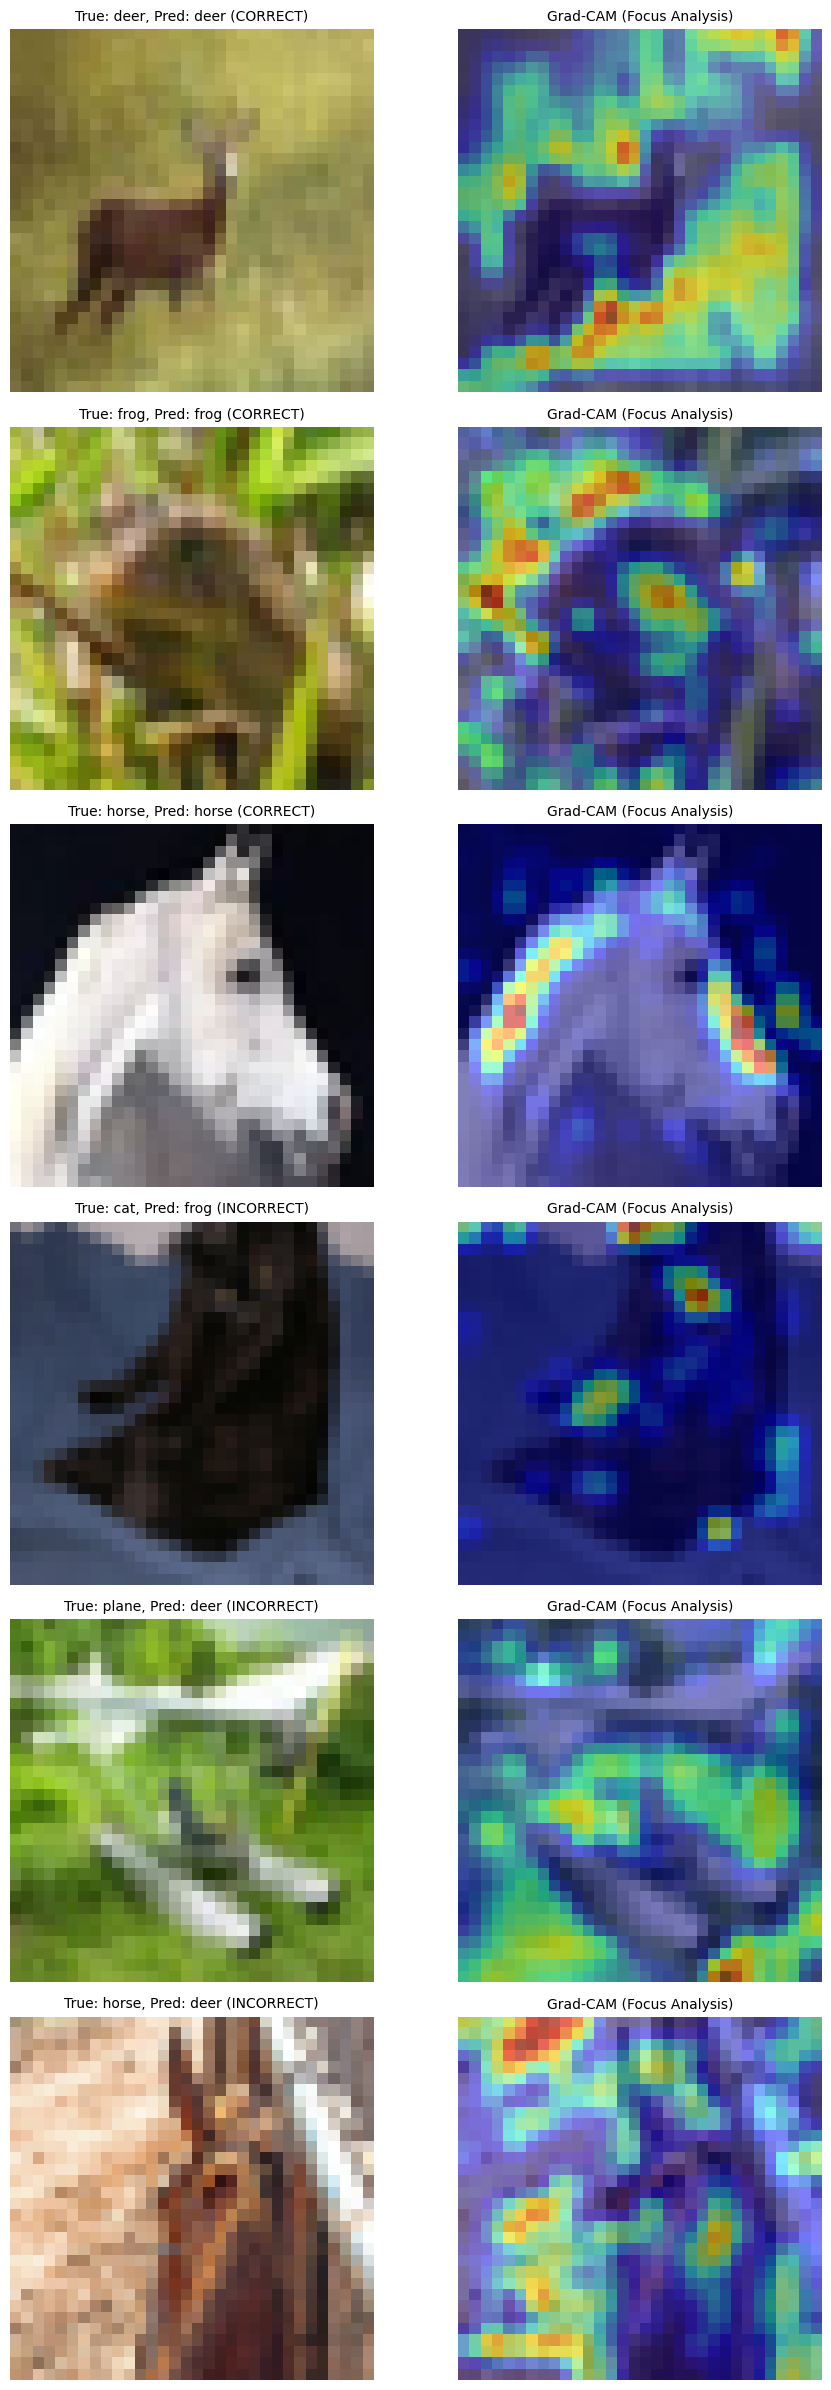

==== Generating Fused (Multi-Layer) Grad-CAM ===
=== Processing Image 1/3 ===


/opt/saturncloud/envs/saturn/lib/python3.10/site-packages/torch/nn/modules/module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


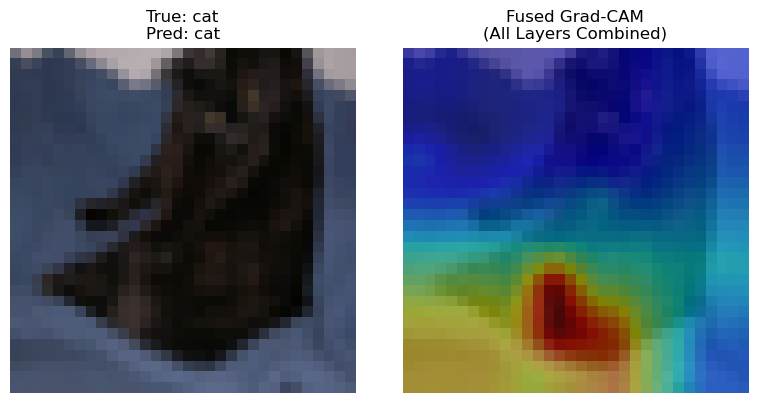

=== Processing Image 2/3 ===


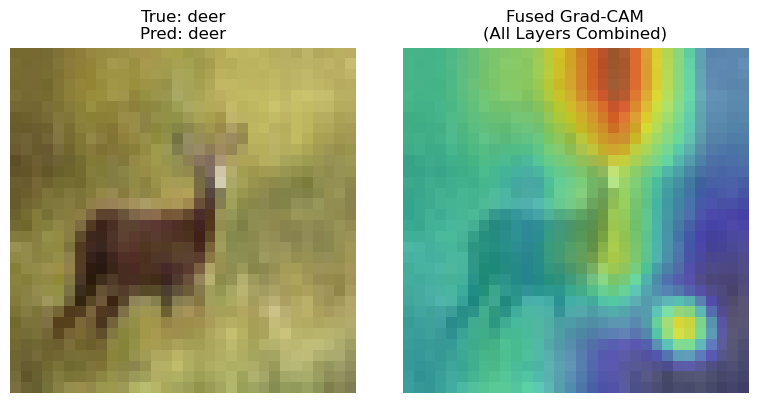

=== Processing Image 3/3 ===


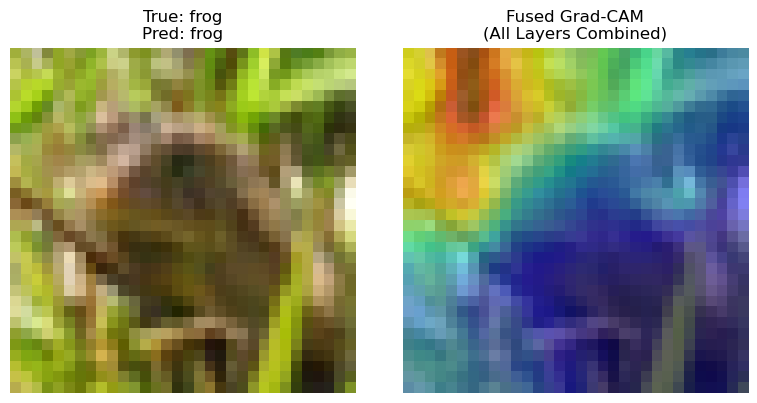

In [ ]:
# @title Phase 6: Grad-CAM usage
target_layer_custom = model_cnn_aug.features[4]
gradcam_custom = GradCAM(model_cnn_aug, target_layer_custom)
class_names = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
visualize_gradcam(model_cnn_aug, gradcam_custom, test_loader, class_names, num_samples=3)

resnet_all_layers = {
    'Layer 1': model_resnet18_finetune.layer1[-1],
    'Layer 2': model_resnet18_finetune.layer2[-1],
    'Layer 3': model_resnet18_finetune.layer3[-1],
    'Layer 4': model_resnet18_finetune.layer4[-1]
}

visualize_fused_gradcam(model_resnet18_finetune, test_loader, resnet_all_layers, class_names, num_samples=3)

خروجی اول در کادر بالا، مربوط به مدل پایه همراه با augmentation است. سه تصویر بعدی مربوط به مدل fine tune از ResNet.

همانطور که از heatmap مدل سفارشی مشخص است، این مدل در حال بررسی جزئیات تصویر می‌باشد و حتی در مواردی (مثل گوزن در ابتدای تصاویر)، با اینکه مدل به درستی برچسب تصویر را حدس زده، اما تمرکز آن بر روی اطراف گوزن و نه خود آن بوده، که مطلوب نیست. همین مسئله باعث شده تا اشتباهات این مدل بیشتر شود و از دقت ایده‌آلی برخوردار نباشد.

در مقابل، heatmap های مدل ResNet نمایان‌گر دقت آن به کلیات است. نواحی قرمز موجود در heatmap مدل ResNet بسیار یکنواخت‌تر و متمرکزتر هستند، در حالی که heatmap مدل سفارشی بسیار پراکنده‌تر و دارای نقاط پرت می‌باشد. مدل ResNet نیز دچار مشکل توجه به حاشیه‌ی تصویر شده، اما در این سه تصویر مورد بررسی، پاسخ درست را حدس زده است. احتمالا با آموزش بیشتر (و حتی افزایش کیفیت تصاویر) می‌توان این پدیده را نیز برطرف کرد.